In [1]:
from sklearn.datasets import load_breast_cancer
from src.clustering import Clustering, entropy_combi
from sklearn.cluster import KMeans
from src.ampute_mar import AmputeMAR

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

import torch
import numpy as np

import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from scipy.stats import rankdata

Error importing in API mode: ImportError("dlopen(/Users/huimin/Documents/UNIGE PhD/research/nonparametric/.venv/lib/python3.11/site-packages/_rinterface_cffi_api.abi3.so, 0x0002): Library not loaded: /Library/Frameworks/R.framework/Versions/4.5-arm64/Resources/lib/libRblas.dylib\n  Referenced from: <1984CB9B-890E-3855-A246-270AC6AC4C62> /Users/huimin/Documents/UNIGE PhD/research/nonparametric/.venv/lib/python3.11/site-packages/_rinterface_cffi_api.abi3.so\n  Reason: tried: '/Library/Frameworks/R.framework/Versions/4.5-arm64/Resources/lib/libRblas.dylib' (no such file), '/System/Volumes/Preboot/Cryptexes/OS/Library/Frameworks/R.framework/Versions/4.5-arm64/Resources/lib/libRblas.dylib' (no such file), '/Library/Frameworks/R.framework/Versions/4.5-arm64/Resources/lib/libRblas.dylib' (no such file)")
Trying to import in ABI mode.


# Breast Cancer Data

In [2]:
# Load data
data = load_breast_cancer(as_frame=False)
X, y = data.data, data.target

# MAR
am = AmputeMAR()
M = am.ampute(torch.tensor(X))[1]
X = torch.tensor(X)

In [3]:
# PCA
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
pca = PCA(n_components=2)
pcs = pca.fit_transform(X_scaled)

In [4]:
# Clustering
M = torch.ones_like(X)
cl = Clustering(X, M, k_range=(0,50), cov_type='diag', random_state=None)
cl.best_k # Check k_range

14

In [5]:
labels0 = cl.which_cluster(X, M) # GM K-clustering
labels_centers = cl.cluster_through_centers(X, M)
labels_entropy_combi = entropy_combi(tau=cl.get_resp(X, M), n_clusters=2).labels

In [20]:
#-------------------------
# Code for plotting
#-------------------------
# Combine labels
clusters = np.column_stack((labels_centers, labels0)).astype(int)

# colors1 = [
#     # "#FFCDD2", "#E57373",
#     "#F44336", "#FF5252", "#FF6B6B",
#     "#FF8A80", "#F66B6B", "#F25C54", "#F04438", "#EF3340",
#     "#E63946", "#E01E37", "#DC143C", "#D00000", "#C1121F",
#     "#B5121B", "#A50000", "#990000", "#800000", "#67000D"
# ]

# colors2 = [
#     # "#E3F2FD", "#BBDEFB", 
#     "#A2DDF2", "#90CAF9", "#75C9E7",
#     "#5BC0DE", "#48BFE3", "#38A6C8", "#219EBC", "#168AAD",
#     "#1976D2", "#1565C0", "#1E88B5", "#2878C8", "#2563EB",
#     "#1D4ED8", "#1746B8", "#123DA5", "#0B2E8A", "#081D58"
# ]

colors1 = [  # Warm: reds, pinks, purples, oranges, yellows
    "#FFE5EC", "#FF80AB", "#FF4081",# "#E91E63", "#C2185B",
    "#9C27B0", "#7B1FA2", "#4A148C", "#B71C1C", "#E53935",
    "#FF5722", "#FF8A33", "#FF9800", "#FDD835", "#FBC02D",
    "#CDDC39", "#7CB342", "#A0522D", "#6D4C41", "#4E0000"
]

colors2 = [  # Cool: blues, cyans, teals, greens, purples
    "#E3F2FD", "#90CAF9", "#42A5F5", "#2196F3", "#1E88E5",
    "#1565C0", "#0D47A1", "#06397A", "#00E5FF", "#00BCD4",
    "#0097A7", "#00838F", "#26A69A", "#43A047", "#9CCC65",
    "#7E57C2", "#5E35B1", "#8E24AA", "#3F51B5", "#0B1E3F"
]



# Group mask
mask = labels_centers == 1

# Dense ranks within each group
_, rank1 = np.unique(clusters[mask, 1], return_inverse=True)
_, rank2 = np.unique(clusters[~mask, 1], return_inverse=True)

# Assign colors
colors = np.empty(len(X), dtype=object)
colors[mask] = np.asarray(colors1)[rank1]
colors[~mask] = np.asarray(colors2)[rank2]

# Construct labels
labs = np.array([
    f"GM center {y} Cluster {x}"
    for x, y in clusters
])

# Mapping: label -> color
color_map = dict(zip(labs, colors))

# One legend handle per unique label
unique_labs = list(color_map)

order = np.lexsort((clusters[:, 1], clusters[:, 0]))
unique_idx = np.unique(clusters, axis=0, return_index=True)[1]
unique_idx = unique_idx[np.argsort(clusters[unique_idx, 0] * (clusters[:, 1].max() + 1) + clusters[unique_idx, 1])]

unique_labs = labs[unique_idx]

handles = [
    Line2D([], [], marker="o", linestyle="", color="w",
           markerfacecolor=color_map[lab], label=lab, markersize=8)
    for lab in unique_labs
]

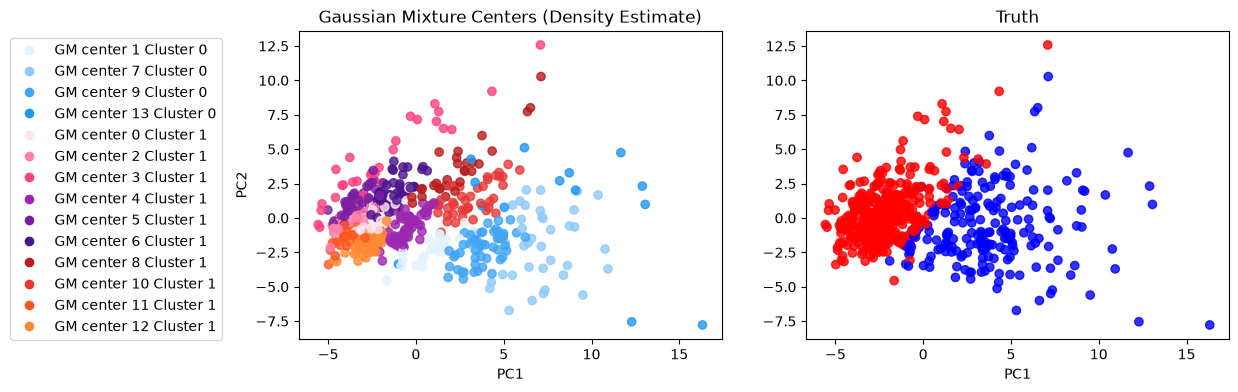

In [21]:
_, axes = plt.subplots(1,2, figsize=(12,4))

axes[0].scatter(pcs[:, 0], pcs[:, 1], c=colors, alpha=0.8)

axes[0].set_xlabel("PC1")
axes[0].set_ylabel("PC2")
axes[0].legend(handles=handles, loc="upper left", bbox_to_anchor=(-0.7, 1))
axes[0].set_title('Gaussian Mixture Centers (Density Estimate)')

axes[1].scatter(pcs[:,0], pcs[:,1], c=np.where(y, 'red', 'blue'), alpha=0.8)
axes[1].set_title('Truth')
axes[1].set_xlabel("PC1")

plt.savefig(
    'results/clustering1.png',
    dpi=300,
    bbox_inches="tight",
    pad_inches=0.2
)

plt.show()

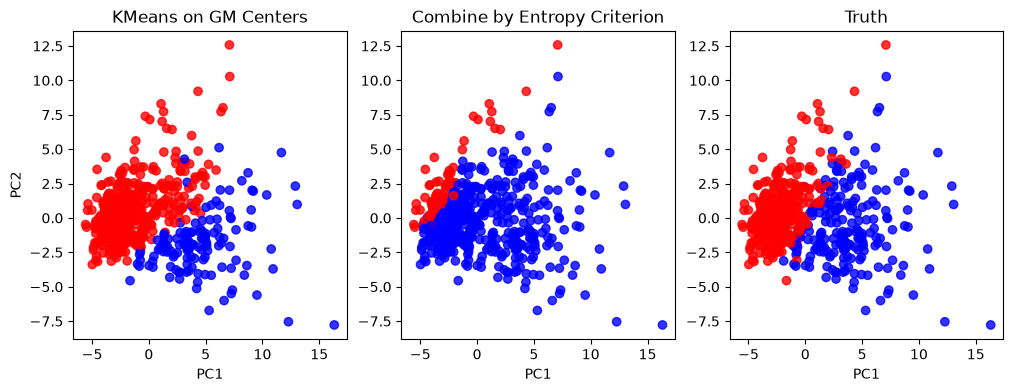

In [23]:
_, axes = plt.subplots(1,3, figsize=(12,4))

axes[0].scatter(pcs[:,0], pcs[:,1], c=np.where(labels_centers, 'red', 'blue'), alpha=0.8)
axes[0].set_title('KMeans on GM Centers')
axes[0].set_xlabel("PC1")
axes[0].set_ylabel("PC2")

axes[1].scatter(pcs[:,0], pcs[:,1], c=np.where(labels_entropy_combi, 'red', 'blue'), alpha=0.8)
axes[1].set_title('Combine by Entropy Criterion')
axes[1].set_xlabel("PC1")

axes[2].scatter(pcs[:,0], pcs[:,1], c=np.where(y, 'red', 'blue'), alpha=0.8)
axes[2].set_title('Truth')
axes[2].set_xlabel("PC1")

plt.savefig('results/clustering2.png',dpi=300,
    bbox_inches="tight",)

plt.show()

On complete data

In [25]:
# Clustering on complete data
Mfull = torch.ones_like(X)
clfull = Clustering(X, Mfull, k_range=(0,50), cov_type='diag', random_state=None)
print(clfull.best_k) # Check k_range

labels0_f = clfull.which_cluster(X, Mfull)
labels_centers_f = clfull.cluster_through_centers(X, Mfull)
labels_entropy_combi_f = entropy_combi(tau=cl.get_resp(X, Mfull), n_clusters=2).labels

15


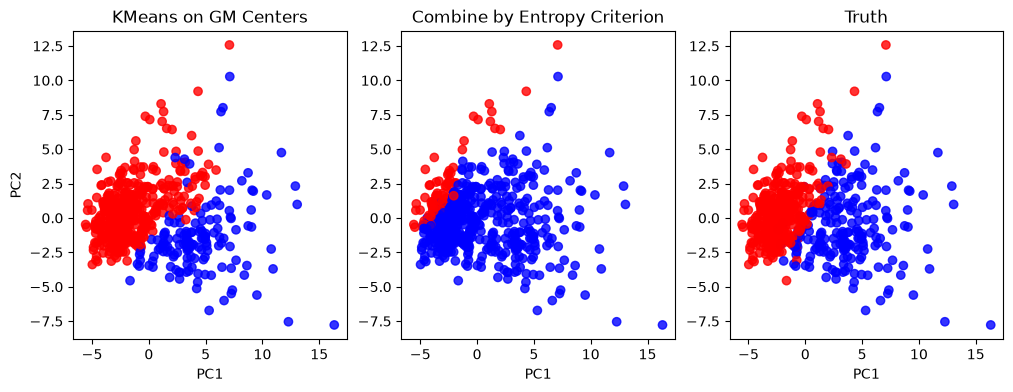

In [27]:
_, axes = plt.subplots(1,3, figsize=(12,4))

axes[0].scatter(pcs[:,0], pcs[:,1], c=np.where(labels_centers_f==0, 'red', 'blue'), alpha=0.8)
axes[0].set_title('KMeans on GM Centers')
axes[0].set_xlabel("PC1")
axes[0].set_ylabel("PC2")

axes[1].scatter(pcs[:,0], pcs[:,1], c=np.where(labels_entropy_combi_f, 'red', 'blue'), alpha=0.8)
axes[1].set_title('Combine by Entropy Criterion')
axes[1].set_xlabel("PC1")

axes[2].scatter(pcs[:,0], pcs[:,1], c=np.where(y, 'red', 'blue'), alpha=0.8)
axes[2].set_title('Truth')
axes[2].set_xlabel("PC1")

plt.savefig('results/clustering3.png',dpi=300,
    bbox_inches="tight",)

plt.show()

# Simulation

In [ ]:
# Simulate data
n = 600
d = 30
norm1 = torch.distributions.MultivariateNormal(loc=torch.tensor([0.0, 0.0]), covariance_matrix=torch.tensor([[1.0,0.5], [0.5,1.0]]))
Y1 = norm1.sample((n,))
norm2 = torch.distributions.MultivariateNormal(loc=torch.tensor([5.0, 5.0]), covariance_matrix=torch.tensor([[1.0,0.5], [0.5,1.0]]))
Y2 = norm2.sample((int(n/2),))

U = torch.distributions.Uniform(0,1).sample((2,30))

X = Y1 @ U
idx = torch.randperm(n)[:int(n/2)]
X[idx] = Y2 @ U
X += torch.randn_like(X)

In [ ]:
am = AmputeMAR()
M = am.ampute(X)[1]

In [ ]:
true_labels = torch.ones(n)
true_labels[idx] = 2

Default of GMMMAR gives shared covariances of each center.

In [ ]:
cl = Clustering(X, M, k_range=(0,20))
topk_ind = cl.cluster_by_logprob(X, M)

kmeans = KMeans(n_clusters=2, n_init=20, random_state=123)
labels_topk = kmeans.fit_predict(topk_ind)

labels_centers = cl.cluster_through_centers(X, M)

pca = PCA(n_components=2)
pcs = pca.fit_transform(X)

In [ ]:
resp_sim = cl.get_resp(X, M)
combires_sim = entropy_combi(resp_sim, n_clusters=2)

In [ ]:
print(cl.log_prob_x(X).sum())

In [ ]:
_, axes = plt.subplots(1,3, figsize=(16,3))
axes[0].scatter(pcs[:,0], pcs[:,1], c=np.where(combires_sim.labels, 'red', 'blue'))
axes[0].set_title('Mcluster')

axes[1].scatter(pcs[:,0], pcs[:,1], c=np.where(labels_centers, 'red', 'blue'))
axes[1].set_title('Center clustering')

axes[2].scatter(pcs[:,0], pcs[:,1], c=np.where(true_labels==1, 'red', 'blue'))
axes[2].set_title('True labels')

plt.show()

In [ ]:
_, axes = plt.subplots(1,2, figsize=(16,4))
axes[0].scatter(pcs[:,0], pcs[:,1], c=np.where(labels_centers, 'red', 'blue'))
axes[0].set_title('First clustering centers')

# axes[1].scatter(pcs[:,0], pcs[:,1], c=np.where(labels_topk, 'red', 'blue'))
# axes[1].set_title('By logprob (N, K)')

axes[1].scatter(pcs[:,0], pcs[:,1], c=np.where(true_labels==1, 'red', 'blue'))
axes[1].set_title('True labels')

plt.show()

In [ ]:
labels = cl.which_cluster(X, M)

cmap = plt.get_cmap("tab10", len(np.unique(labels)))

for k in np.unique(labels):
    mask = labels == k
    a = int(k in np.where(cl.center_labels==1)[0])
    plt.scatter(
        pcs[mask, 0],
        pcs[mask, 1],
        label=f"Cluster {k}, Group {a}",
        alpha= (a + 1) / 2,
        c=cmap(k),
        edgecolors="black",
        linewidths=0.3
    )

plt.xlabel("PC1")
plt.ylabel("PC2")
plt.legend(title="Clusters", loc="upper left", bbox_to_anchor=(1.02, 1))
plt.show()

In [ ]:
cl = Clustering(X, M, k_range=(0,20))
topk_ind = cl.cluster_by_logprob(X, M)

kmeans = KMeans(n_clusters=2, n_init=20, random_state=123)
labels_topk = kmeans.fit_predict(topk_ind)


labels_centers = cl.cluster_through_centers(X, M)

pca = PCA(n_components=2)
pcs = pca.fit_transform(X)

In [ ]:
print(cl.log_prob_x(X).sum())

In [ ]:
_, axes = plt.subplots(1,2, figsize=(16,4))

axes[0].scatter(pcs[:,0], pcs[:,1], c=np.where(labels_centers, 'red', 'blue'))
axes[0].set_title('First clustering centers')

# axes[1].scatter(pcs[:,0], pcs[:,1], c=np.where(labels_topk, 'red', 'blue'))
# axes[1].set_title('By logprob (N, K)')

axes[1].scatter(pcs[:,0], pcs[:,1], c=np.where(true_labels==1, 'red', 'blue'))
axes[1].set_title('True labels')

plt.show()

In [ ]:
labels = cl.which_cluster(X, M)

for k in np.unique(labels):
    mask = labels == k
    a = int(k in np.where(cl.center_labels==1)[0])
    plt.scatter(
        pcs[mask, 0],
        pcs[mask, 1],
        label=f"Cluster {k}, Group {a}",
        alpha= (a + 1) / 2
    )

plt.xlabel("PC1")
plt.ylabel("PC2")
plt.legend(title="Clusters", loc="upper left", bbox_to_anchor=(1.02, 1))
plt.show()